# 03 — Imagens: padronização, tensor e formato

Notebook equivalente a `src/images/`. Cobre as etapas 5 a 7 de `.claude/specs/etapas_do_projeto.md`:
1. **Opções de formato:** protótipo que serviu à decisão do usuário.
2. **Partições da CV:** 5-fold estratificada.
3. **Tensor e padronização por canal:** só com o treino de cada fold.
4. **Imagem na curva de Hilbert.**

Entrada: `data/interim/`, gerado pelo `02_features`. Coorte de modelagem (decisão do usuário,
2026-10-08): 336 pacientes rotulados, sem POLE.

Saída em `data/processed/`:
- `coorte_cv.csv`: amostra, subtipo, `classe_idx` (CIN=0, MSI=1, GS=2, EBV=3) e `fold` de teste;
- `tensor_bruto.npy`: `(336, 3, 17.818)`, com `NaN` preservado;
- `padronizacao.json`: média e desvio por canal, por fold, só do treino;
- `layout_hilbert.csv`: gene → linha e coluna do pixel.

Quem treina aplica `padronizar()` e `para_hilbert()`, definidas aqui.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
INTERIM = RAIZ / "data" / "interim"
CLASSES = ["STAD_CIN", "STAD_MSI", "STAD_GS", "STAD_EBV"]
CANAIS = ["mutacao", "cnv", "metilacao"]

genes = pd.read_csv(INTERIM / "genes.csv", index_col="gene")
amostras = pd.read_csv(INTERIM / "amostras.csv")
canais = {nome: pd.read_parquet(INTERIM / f"{nome}.parquet").T for nome in CANAIS}
coorte = amostras[amostras.subtipo.isin(CLASSES)].reset_index(drop=True)
assert len(coorte) == 336 and all(list(m.columns) == list(genes.index) for m in canais.values())
N = len(genes)
print(f"coorte: {len(coorte)} {coorte.subtipo.value_counts().reindex(CLASSES).to_dict()} · genes por canal: {N:,}")

coorte: 336 {'STAD_CIN': 202, 'STAD_MSI': 59, 'STAD_GS': 46, 'STAD_EBV': 29} · genes por canal: 17,818


## Formato da imagem — opções

O tensor de cada paciente é `3 canais × 17.818 genes`, em ordem cromossômica. O formato só decide
**onde cada gene vira pixel**. Todas as opções preservam a ordem e usam a mesma tabela gene → posição,
então qualquer pixel volta para o seu gene.

| # | Formato | Como os genes são dispostos |
|---|---|---|
| 1 | **Vetor 1D** | uma linha de 17.818 posições, na ordem do genoma; vai para a Small CNN (vetor 1D) |
| 2 | **Grade linear** | o vetor quebrado em linhas, como texto numa página |
| 3 | **Curva de Hilbert** | o vetor "dobrado" numa curva que preenche o quadrado sem sair da vizinhança |
| 4 | **Circular em anéis** | o vetor enrolado em anéis, do centro para fora (chr1 no centro, X na borda) |
| 5 | **Circular em setores** | o genoma dá a volta no círculo, e cada cromossomo vira uma fatia |

In [2]:
def grade_linear(n):
    lado = int(np.ceil(np.sqrt(n)))
    i = np.arange(n)
    return np.c_[i // lado, i % lado], (int(np.ceil(n / lado)), lado)


def _gilbert(x, y, ax, ay, bx, by):
    # curva de Hilbert generalizada para retângulos quaisquer (algoritmo "gilbert", J. Červený)
    w, h = abs(ax + ay), abs(bx + by)
    dax, day, dbx, dby = np.sign(ax), np.sign(ay), np.sign(bx), np.sign(by)
    if h == 1:
        for _ in range(w):
            yield x, y
            x, y = x + dax, y + day
        return
    if w == 1:
        for _ in range(h):
            yield x, y
            x, y = x + dbx, y + dby
        return
    ax2, ay2, bx2, by2 = ax // 2, ay // 2, bx // 2, by // 2
    w2, h2 = abs(ax2 + ay2), abs(bx2 + by2)
    if 2 * w > 3 * h:
        if w2 % 2 and w > 2:
            ax2, ay2 = ax2 + dax, ay2 + day
        yield from _gilbert(x, y, ax2, ay2, bx, by)
        yield from _gilbert(x + ax2, y + ay2, ax - ax2, ay - ay2, bx, by)
    else:
        if h2 % 2 and h > 2:
            bx2, by2 = bx2 + dbx, by2 + dby
        yield from _gilbert(x, y, bx2, by2, ax2, ay2)
        yield from _gilbert(x + bx2, y + by2, ax, ay, bx - bx2, by - by2)
        yield from _gilbert(x + (ax - dax) + (bx2 - dbx), y + (ay - day) + (by2 - dby),
                            -bx2, -by2, -(ax - ax2), -(ay - ay2))


def curva_hilbert(n):
    lado = int(np.ceil(np.sqrt(n)))
    altura = int(np.ceil(n / lado))
    caminho = np.array(list(_gilbert(0, 0, lado, 0, 0, altura)))  # (x, y), começa no canto
    return caminho[:n, ::-1], (altura, lado)


def _disco(area_minima, interno=0.0):
    # pixels de um disco (ou anel, se interno > 0) com pelo menos `area_minima` pixels
    raio = int(np.ceil(np.sqrt(area_minima / (np.pi * (1 - interno ** 2))))) + 1
    yy, xx = np.mgrid[-raio:raio + 1, -raio:raio + 1]
    r = np.hypot(yy, xx)
    ang = np.mod(np.arctan2(xx, -yy), 2 * np.pi)  # 0 = meio-dia, sentido horário
    dentro = (r <= raio) & (r >= interno * raio)
    return np.c_[yy[dentro] + raio, xx[dentro] + raio], r[dentro], ang[dentro], (2 * raio + 1, 2 * raio + 1)


def circular_aneis(n):
    pos, r, ang, forma = _disco(n)
    ordem = np.lexsort((ang, np.floor(r)))  # anel por anel, do centro para fora; dentro do anel, pelo ângulo
    return pos[ordem][:n], forma


def circular_setores(n, interno=0.4):
    pos, r, ang, forma = _disco(n, interno)
    raio_medio = forma[0] / 2 * (1 + interno) / 2
    n_raios = int(2 * np.pi * raio_medio)  # raios de ~1 pixel de largura no meio do anel
    raio_idx = (ang / (2 * np.pi) * n_raios).astype(int)
    serpente = np.where(raio_idx % 2 == 0, r, -r)  # para fora num raio, para dentro no seguinte
    ordem = np.lexsort((serpente, raio_idx))
    return pos[ordem][:n], forma


FORMATOS = {"grade linear": grade_linear, "curva de Hilbert": curva_hilbert,
            "circular em anéis": circular_aneis, "circular em setores": circular_setores}
layouts = {nome: f(N) for nome, f in FORMATOS.items()}

# autotestes: cada gene num pixel próprio, dentro da imagem; na Hilbert, passos sempre entre vizinhos
for nome, (pos, forma) in layouts.items():
    assert len(pos) == N and len({tuple(p) for p in pos}) == N, f"{nome}: pixel repetido"
    assert (pos >= 0).all() and (pos[:, 0] < forma[0]).all() and (pos[:, 1] < forma[1]).all(), f"{nome}: fora da imagem"
passos = np.abs(np.diff(layouts["curva de Hilbert"][0], axis=0)).sum(axis=1)
assert (passos == 1).all(), "Hilbert: passo entre pixels não vizinhos"
print("layouts: ok")

layouts: ok


### Quanto cada formato preserva a vizinhança do genoma

Numa CNN, o filtro olha para pixels vizinhos. Se dois pixels vizinhos são genes vizinhos no genoma,
padrões contíguos, como um segmento de CNV que pega dezenas de genes seguidos, viram manchas
compactas. Se não forem, o filtro mistura regiões sem relação. Para cada par de pixels vizinhos
(cima/baixo/lado):
- **vizinho no genoma**: % dos pares a até 10 genes de distância;
- **mesmo cromossomo**: % dos pares no mesmo cromossomo;
- **distância mediana** entre os dois genes, na ordem do genoma.

No vetor 1D, todo vizinho é o gene seguinte (100%), mas o filtro só vê uma dimensão.

In [3]:
crom = genes.cromossomo.to_numpy()
linhas = []
for nome, (pos, forma) in layouts.items():
    grade = np.full(forma, -1)
    grade[pos[:, 0], pos[:, 1]] = np.arange(N)
    pares = [(grade[:, :-1], grade[:, 1:]), (grade[:-1, :], grade[1:, :])]
    a = np.concatenate([p[(p >= 0) & (q >= 0)] for p, q in pares])
    b = np.concatenate([q[(p >= 0) & (q >= 0)] for p, q in pares])
    d = np.abs(a - b)
    linhas.append({"formato": nome, "imagem": f"{forma[0]}×{forma[1]}", "pixels vazios %": round(100 * (1 - N / grade.size), 1),
                   "vizinho no genoma %": round(100 * (d <= 10).mean(), 1),
                   "mesmo cromossomo %": round(100 * (crom[a] == crom[b]).mean(), 1),
                   "distância mediana (genes)": int(np.median(d))})
linhas.insert(0, {"formato": "vetor 1D", "imagem": f"1×{N}", "pixels vazios %": 0.0, "vizinho no genoma %": 100.0,
                  "mesmo cromossomo %": round(100 * (crom[:-1] == crom[1:]).mean(), 1), "distância mediana (genes)": 1})
pd.DataFrame(linhas).set_index("formato")

,imagem,pixels vazios %,vizinho no genoma %,mesmo cromossomo %,distância mediana (genes)
formato,,,,,
vetor 1D,1×17818,0.0,100.0,99.9,1
grade linear,133×134,0.0,50.0,91.6,1
curva de Hilbert,133×134,0.0,78.2,96.2,1
circular em anéis,155×155,25.8,37.2,75.0,212
circular em setores,169×169,37.6,44.4,95.9,20


### Como fica um paciente em cada formato

Paciente CIN com muita alteração de número de cópias, para ver como os segmentos aparecem. As cores
usam **transformações fixas, só para visualizar**: mutação log(1 + contagem); CNV log2 cortado em ±1
(azul = perda, vermelho = ganho); metilação = beta. Não há estatística da população, logo nenhum
vazamento. A padronização de verdade é a da etapa 5, por fold. Cinza = ausente (`NaN`; inclui a
metilação do X); branco = pixel vazio do formato.

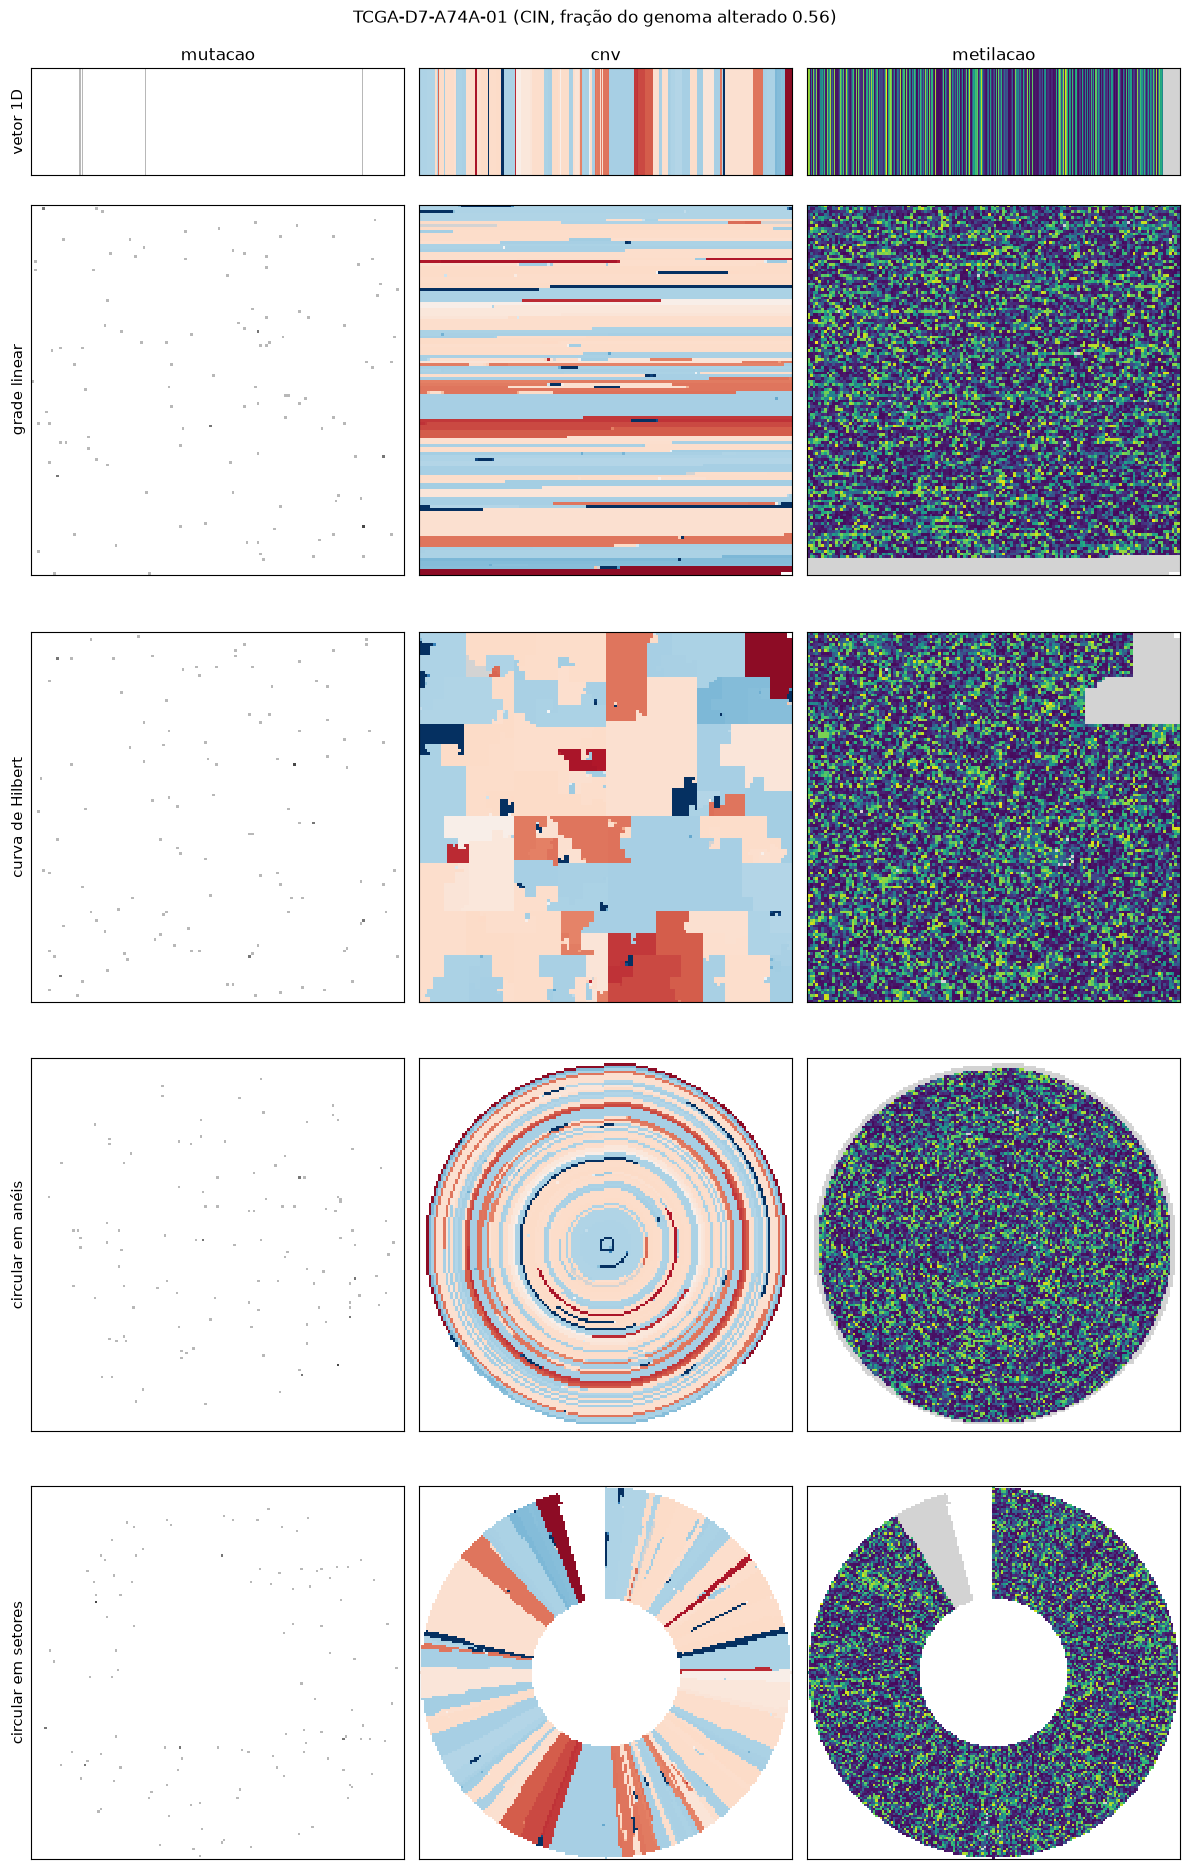

In [4]:
fga = (canais["cnv"].loc[coorte.amostra].abs() > 0.2).mean(axis=1)
exemplo = fga[coorte.set_index("amostra").subtipo == "STAD_CIN"].sort_values().index[-20]  # CIN de aneuploidia alta, não extrema
VISUAL = {"mutacao": (lambda v: np.log1p(v), "Greys", 0, np.log1p(5)),
          "cnv": (lambda v: np.clip(v, -1, 1), "RdBu_r", -1, 1),
          "metilacao": (lambda v: v, "viridis", 0, 1)}


def desenhar(ax, valores, pos, forma, cmap, vmin, vmax):
    img = np.full(forma, np.nan)
    img[pos[:, 0], pos[:, 1]] = valores
    vazio = np.ones(forma, bool)
    vazio[pos[:, 0], pos[:, 1]] = False
    mapa = plt.get_cmap(cmap).copy()
    mapa.set_bad("lightgray")
    ax.imshow(img, cmap=mapa, vmin=vmin, vmax=vmax, interpolation="nearest", aspect="auto" if forma[0] == 1 else "equal")
    ax.imshow(np.ma.masked_where(~vazio, vazio), cmap="binary_r", vmin=0, vmax=1, interpolation="nearest",
              aspect="auto" if forma[0] == 1 else "equal")
    ax.set_xticks([]), ax.set_yticks([])


todos = {"vetor 1D": (np.c_[np.zeros(N, int), np.arange(N)], (1, N)), **layouts}
fig, eixos = plt.subplots(len(todos), 3, figsize=(12, 19), gridspec_kw={"height_ratios": [0.25] + [1] * len(layouts)})
for i, (nome, (pos, forma)) in enumerate(todos.items()):
    for j, canal in enumerate(CANAIS):
        transf, cmap, vmin, vmax = VISUAL[canal]
        desenhar(eixos[i, j], transf(canais[canal].loc[exemplo].to_numpy()), pos, forma, cmap, vmin, vmax)
        if i == 0:
            eixos[i, j].set_title(canal, fontsize=12)
    eixos[i, 0].set_ylabel(nome, fontsize=11)
fig.suptitle(f"{exemplo} (CIN, fração do genoma alterado {fga[exemplo]:.2f})", y=0.995)
fig.tight_layout()

### O mesmo formato, uma paciente de cada classe

Canal de CNV na curva de Hilbert e no circular em setores, os dois 2D que mais preservam a vizinhança
(ver a tabela). A assinatura de cada classe tem de aparecer: CIN cheio de blocos, GS quase liso.

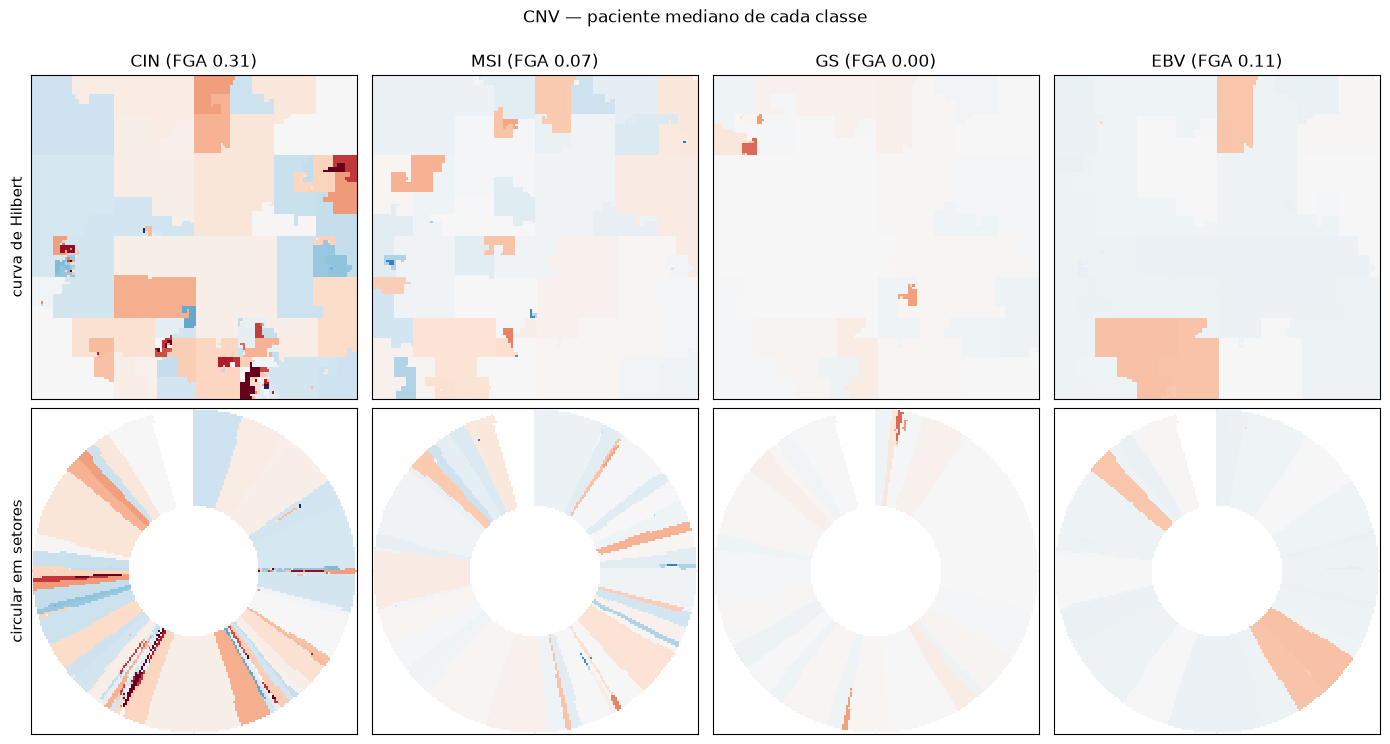

In [5]:
exemplos = {c: fga[coorte.set_index("amostra").subtipo == c].median() for c in CLASSES}
por_classe = {c: (fga[coorte.set_index("amostra").subtipo == c] - exemplos[c]).abs().idxmin() for c in CLASSES}  # paciente mediano da classe
fig, eixos = plt.subplots(2, 4, figsize=(14, 7.5))
for i, nome in enumerate(["curva de Hilbert", "circular em setores"]):
    pos, forma = layouts[nome]
    for j, (classe, amostra) in enumerate(por_classe.items()):
        desenhar(eixos[i, j], np.clip(canais["cnv"].loc[amostra].to_numpy(), -1, 1), pos, forma, "RdBu_r", -1, 1)
        eixos[0, j].set_title(f"{classe.removeprefix('STAD_')} (FGA {fga[amostra]:.2f})")
    eixos[i, 0].set_ylabel(nome, fontsize=11)
fig.suptitle("CNV — paciente mediano de cada classe", y=1.0)
fig.tight_layout()

## Decisões do usuário (2026-10-08)

- **Formato principal: curva de Hilbert** (133×134). Depois, comparação com o **vetor 1D**.
- **Validação: CV 5-fold estratificada** por subtipo.

## Etapa 5a — partições da CV

Cada classe é embaralhada (semente fixa) e distribuída em rodízio pelos 5 folds. A contagem continua de
uma classe para a outra, para as sobras não caírem sempre no fold 0. Resultado: todo paciente fica em
exatamente um fold de teste, e as classes ficam equilibradas entre os folds (diferença máxima de 1).
Feito com numpy, sem dependência nova.

In [6]:
SEED, K = 42, 5
PROCESSED = RAIZ / "data" / "processed"

rng = np.random.default_rng(SEED)
coorte["classe_idx"] = coorte.subtipo.map({c: i for i, c in enumerate(CLASSES)})  # CIN=0, MSI=1, GS=2, EBV=3
coorte["fold"] = -1
deslocamento = 0
for classe in CLASSES:
    indices = rng.permutation(coorte.index[coorte.subtipo == classe].to_numpy())
    coorte.loc[indices, "fold"] = (np.arange(len(indices)) + deslocamento) % K
    deslocamento += len(indices)

por_fold = pd.crosstab(coorte.subtipo, coorte.fold).reindex(CLASSES)
assert (coorte.fold >= 0).all() and (por_fold.max(axis=1) - por_fold.min(axis=1) <= 1).all()
PROCESSED.mkdir(parents=True, exist_ok=True)
coorte[["amostra", "paciente", "subtipo", "classe_idx", "fold"]].to_csv(PROCESSED / "coorte_cv.csv", index=False)
por_fold.assign(total=por_fold.sum(axis=1)).rename_axis(index="classe", columns="fold de teste")

fold de teste,0,1,2,3,4,total
classe,,,,,,
STAD_CIN,41,41,40,40,40,202
STAD_MSI,12,11,12,12,12,59
STAD_GS,9,10,9,9,9,46
STAD_EBV,6,5,6,6,6,29


## Etapas 5b e 6 — tensor e padronização por canal, só com o treino

- **Tensor bruto:** `(336 amostras, 3 canais, 17.818 genes)`. A posição `i` é o mesmo gene nos três
  canais, e o `NaN` é preservado.
- **Padronização por canal** (fluxograma: "estatística só do treino"):
  - para cada fold, **uma média e um desvio por canal**, calculados nos pacientes de treino (os outros
    4 folds), sobre todos os genes e ignorando `NaN`;
  - aplicação: `z = (x − média) / desvio`;
  - **a mutação entra em `log(1 + contagem)` antes** (decisão do usuário, 2026-10-09), nas estatísticas e na
    aplicação. Ela não resolve o z ≈ 7,6 da variante isolada (o canal é 98,5% zeros), mas comprime a cauda do
    hipermutado para a ordem dos extremos da CNV. Fica registrada no `padronizacao.json`
    (`"transformacao": "log1p"`), e o `tensor_bruto.npy` continua bruto;
  - depois, ausente vira **0**, que é a média do canal no treino. Isso inclui a metilação do X, que vira
    0 constante e não carrega sexo.
- Não se gravam 5 cópias padronizadas do tensor (5 × 72 MB). Grava-se o tensor bruto uma vez e os 6
  números de cada fold; `padronizar()` aplica na hora de treinar.

In [7]:
import json

tensor = np.stack([canais[c].loc[coorte.amostra].to_numpy(np.float32) for c in CANAIS], axis=1)
fold = coorte.fold.to_numpy()


def transformar(x):
    x = x.copy()
    x[:, 0] = np.log1p(x[:, 0])  # mutação em log(1 + contagem); CNV e metilação ficam como estão
    return x


def estatisticas(x):
    return {canal: {"media": float(np.nanmean(x[:, i])), "desvio": float(np.nanstd(x[:, i]))} for i, canal in enumerate(CANAIS)}


def padronizar(x, stats):
    x = transformar(x)
    media = np.array([stats[c]["media"] for c in CANAIS], np.float32)[None, :, None]
    desvio = np.array([stats[c]["desvio"] for c in CANAIS], np.float32)[None, :, None]
    return np.nan_to_num((x - media) / desvio, nan=0.0)


padronizacao = {k: estatisticas(transformar(tensor[fold != k])) for k in range(K)}  # fold k = teste; estatística só dos outros
for stats in padronizacao.values():
    stats["mutacao"]["transformacao"] = "log1p"  # o 04_models e o 05_eval conferem isto antes de padronizar

# conferência: no treino de cada fold, cada canal fica com média ~0 e desvio ~1 (antes de preencher o NaN)
for k, stats in padronizacao.items():
    z = (transformar(tensor[fold != k]) - np.array([stats[c]["media"] for c in CANAIS])[None, :, None]) / \
        np.array([stats[c]["desvio"] for c in CANAIS])[None, :, None]
    assert np.allclose(np.nanmean(z, axis=(0, 2)), 0, atol=1e-3) and np.allclose(np.nanstd(z, axis=(0, 2)), 1, atol=1e-3)

np.save(PROCESSED / "tensor_bruto.npy", tensor)
(PROCESSED / "padronizacao.json").write_text(json.dumps(padronizacao, indent=1))
print(f"tensor {tensor.shape} · NaN por canal: {dict(zip(CANAIS, np.isnan(tensor).mean(axis=(0, 2)).round(4)))}")
pd.DataFrame({(k, c): v for k, s in padronizacao.items() for c, v in s.items()}).T.rename_axis(["fold", "canal"]).round(4).unstack("canal")

tensor (336, 3, 17818) · NaN por canal: {'mutacao': np.float64(0.0), 'cnv': np.float64(0.0011), 'metilacao': np.float64(0.0465)}


media                        desvio                      \
canal       cnv metilacao   mutacao       cnv metilacao   mutacao   
fold                                                                
0      0.001675  0.276313  0.010892  0.212766  0.254195  0.089417   
1       0.00194  0.276215  0.010477  0.209314  0.253927  0.087483   
2        0.0015  0.275384   0.01078  0.212341  0.254149  0.089123   
3      0.000812  0.275001  0.010947  0.214291  0.253381  0.089817   
4      0.001674  0.275592  0.011062  0.213461   0.25446  0.090455   

      transformacao                    
canal           cnv metilacao mutacao  
fold                                   
0               NaN       NaN   log1p  
1               NaN       NaN   log1p  
2               NaN       NaN   log1p  
3               NaN       NaN   log1p  
4               NaN       NaN   log1p

## Etapa 7 — imagem na curva de Hilbert

`para_hilbert()` recebe o tensor padronizado e devolve `(amostras, 3, 133, 134)`. A tabela gene → pixel
vai para `layout_hilbert.csv` e leva qualquer pixel de volta ao seu gene. Os 4 pixels sem gene
(133 × 134 = 17.822) ficam em 0. Para o vetor 1D, a comparação posterior, basta o tensor padronizado
como está: `(amostras, 3, 17.818)`.

In [8]:
pos_hilbert, forma_hilbert = curva_hilbert(N)


def para_hilbert(x):
    img = np.zeros((x.shape[0], x.shape[1], *forma_hilbert), np.float32)
    img[:, :, pos_hilbert[:, 0], pos_hilbert[:, 1]] = x
    return img


# ida e volta: o pixel de cada gene guarda o valor daquele gene, nos três canais
z0 = padronizar(tensor[fold == 0], padronizacao[0])
imgs0 = para_hilbert(z0)
for g in ["MLH1", "CDKN2A", "TP53", "ERBB2"]:
    i = genes.index.get_loc(g)
    assert np.array_equal(imgs0[:, :, pos_hilbert[i, 0], pos_hilbert[i, 1]], z0[:, :, i]), g
pd.DataFrame({"gene": genes.index, "linha": pos_hilbert[:, 0], "coluna": pos_hilbert[:, 1]}).to_csv(
    PROCESSED / "layout_hilbert.csv", index=False)

print(f"imagens do fold 0 (teste): {imgs0.shape}")
pd.DataFrame({canal: {"mín": z0[:, c].min(), "máx": z0[:, c].max(), "% |z| > 5": 100 * (np.abs(z0[:, c]) > 5).mean()}
              for c, canal in enumerate(CANAIS)}).round(3)

imagens do fold 0 (teste): (68, 3, 133, 134)


,mutacao,cnv,metilacao
mín,-0.122,-22.297,-1.057
máx,33.381,17.514,2.812
% |z| > 5,1.453,0.299,0.000


Text(0.5, 0.92, 'Imagem de 3 canais na curva de Hilbert — paciente mediano de cada classe')

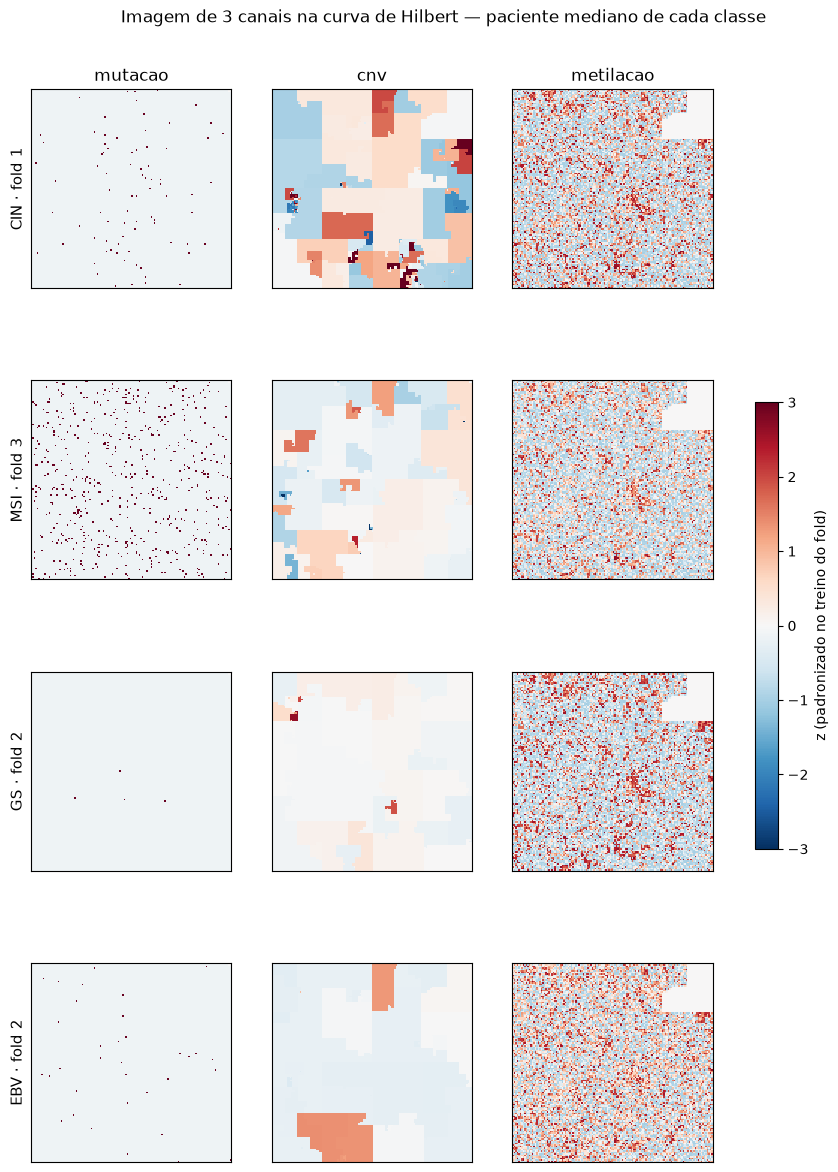

In [9]:
# a imagem final: paciente mediano de cada classe, padronizado com a estatística do treino do SEU fold
fig, eixos = plt.subplots(4, 3, figsize=(11, 14.5))
for i, (classe, amostra) in enumerate(por_classe.items()):
    j = coorte.index[coorte.amostra == amostra][0]
    img = para_hilbert(padronizar(tensor[[j]], padronizacao[fold[j]]))[0]
    for c, canal in enumerate(CANAIS):
        im = eixos[i, c].imshow(img[c], cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
        eixos[i, c].set_xticks([]), eixos[i, c].set_yticks([])
        if i == 0:
            eixos[i, c].set_title(canal)
    eixos[i, 0].set_ylabel(f"{classe.removeprefix('STAD_')} · fold {fold[j]}", fontsize=11)
fig.colorbar(im, ax=eixos, shrink=0.4, label="z (padronizado no treino do fold)")
fig.suptitle("Imagem de 3 canais na curva de Hilbert — paciente mediano de cada classe", y=0.92)

### É uma imagem só, com 3 canais por pixel

A figura acima separa os canais para dar para ver cada um. A imagem de cada paciente, porém, é **um
único array `(3, 133, 134)`**: cada pixel é um gene e guarda três números (mutação, CNV e metilação),
como o R, G e B de uma foto. Abaixo, a mesma imagem como cor, com **R = mutação, G = CNV e
B = metilação** (z cortado em ±3 só para exibir), e a leitura de um pixel.

MLH1 é o pixel (linha 61, coluna 42) de toda imagem. Os três valores (z) desse pixel em cada paciente:


,CIN,MSI,GS,EBV
mutacao,-0.12,-0.12,-0.12,-0.12
cnv,-0.91,-0.03,-0.04,-0.22
metilacao,-0.76,-0.53,-0.80,-0.56


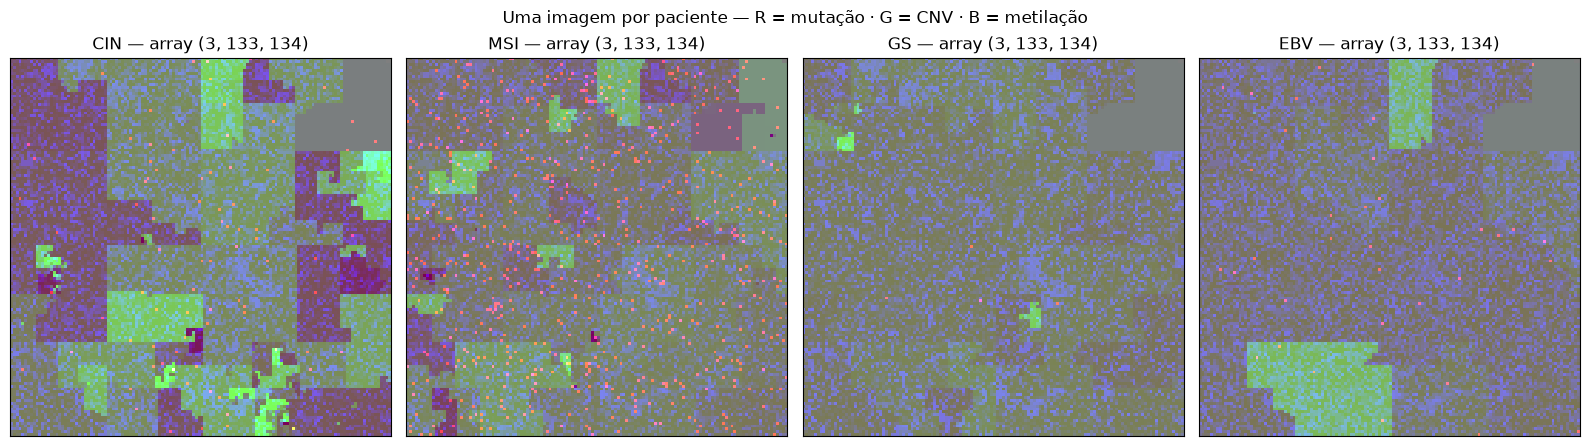

In [10]:
fig, eixos = plt.subplots(1, 4, figsize=(16, 4.6))
imagens = {}

for ax, (classe, amostra) in zip(eixos, por_classe.items()):
    j = coorte.index[coorte.amostra == amostra][0]
    img = para_hilbert(padronizar(tensor[[j]], padronizacao[fold[j]]))[0]  # (3, 133, 134): UMA imagem
    imagens[classe] = img
    rgb = (np.clip(img, -3, 3) + 3) / 6  # cada canal em [0, 1], só para exibir
    ax.imshow(np.moveaxis(rgb, 0, -1), interpolation="nearest")  # (133, 134, 3): R=mutação, G=CNV, B=metilação
    ax.set_title(f"{classe.removeprefix('STAD_')} — array {img.shape}")
    ax.set_xticks([]), ax.set_yticks([])
fig.suptitle("Uma imagem por paciente — R = mutação · G = CNV · B = metilação")
fig.tight_layout()

# um pixel = um gene = três números
i = genes.index.get_loc("MLH1")
r, c = pos_hilbert[i]
print(f"MLH1 é o pixel (linha {r}, coluna {c}) de toda imagem. Os três valores (z) desse pixel em cada paciente:")
pd.DataFrame({classe.removeprefix("STAD_"): dict(zip(CANAIS, img[:, r, c].round(2))) for classe, img in imagens.items()})